Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.3 MB/s eta 0:00:00
bw (650000,) std 0.466
em (650000,) std 0.73
ma (650000,) std 0.193
SNR check passed


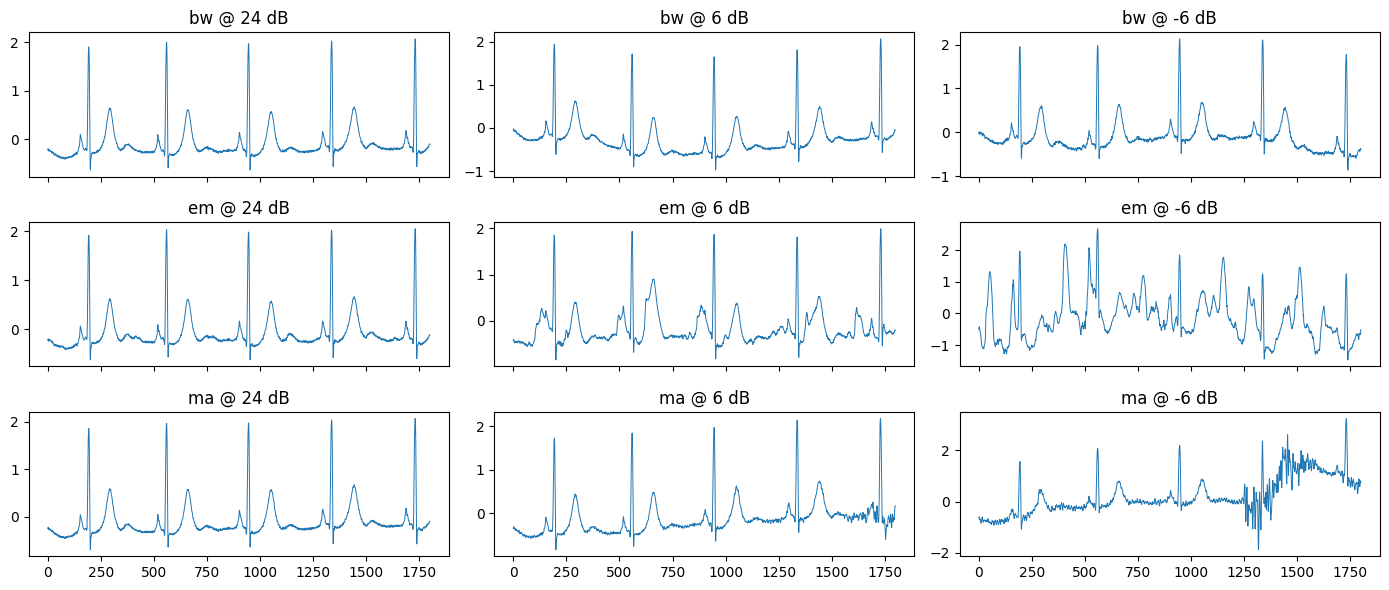

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q wfdb
import os, sys, json, zlib, hashlib, time
os.chdir('/content/drive/MyDrive/FYP'); sys.path.insert(0, os.getcwd())


import sys; sys.path.insert(0, '..')
import numpy as np, matplotlib.pyplot as plt
from src import config as C
from src.data import load_signal
from src.noise import *

# cell 2: noise records as loaded (check these numbers against PhysioNet's description)
for k in NOISE_TYPES:
    nz = load_noise(k); print(k, nz.shape, 'std', nz.std().round(3))

# cell 3: achieved SNR must match the target
sig = load_signal(106)
for k in NOISE_TYPES:
    for snr in [24, 12, 0, -6]:
        noisy = noise_fn(k, snr, 'dev')(106, sig)
        got = 10 * np.log10(np.var(sig) / np.var(noisy - sig))
        assert abs(got - snr) < 0.5, (k, snr, got)
print('SNR check passed')

# cell 4: visual check
fig, ax = plt.subplots(3, 3, figsize=(14, 6), sharex=True)
seg = slice(72000, 72000 + 5 * C.FS)
for i, k in enumerate(NOISE_TYPES):
    for j, snr in enumerate([24, 6, -6]):
        ax[i, j].plot(noise_fn(k, snr, 'dev')(106, sig)[seg], lw=0.7)
        ax[i, j].set_title(f'{k} @ {snr} dB')
plt.tight_layout()

In [2]:
# ===== notebook 04, ADDENDUM cell (run after the existing cells; reads no DS2 data) =====
# Checks still missing before DS2: all six SNRs, the 'test' pool that DS2 will use, pool separation, reproducibility,
# and the provenance of the added noise (it must really be built from the pool's chunks). Record 106 is a DS1 record.
import zlib
sig = load_signal(106)

def rebuild(kind, snr, rec_id, pool, signal):
    """Re-derive the added noise from src.noise's own recipe (same seed, same chunk draw, same scaling)."""
    nz = load_noise(kind); starts = chunk_starts(len(nz), pool)
    rng = np.random.default_rng(zlib.crc32(f'{kind}-{snr}-{rec_id}-{pool}'.encode()))
    pick = rng.choice(starts, int(np.ceil(len(signal) / CHUNK)), replace=True)
    z = np.concatenate([nz[s:s + CHUNK] for s in pick])[:len(signal)]
    z = z - z.mean()
    return pick, np.sqrt(np.var(signal) / (np.var(z) * 10 ** (snr / 10))) * z

for k in NOISE_TYPES:
    nz = load_noise(k)
    dev_s, test_s = set(chunk_starts(len(nz), 'dev')), set(chunk_starts(len(nz), 'test'))
    assert dev_s and test_s and not (dev_s & test_s), f'{k}: dev and test chunk pools overlap'
    for pool, own, other in [('dev', dev_s, test_s), ('test', test_s, dev_s)]:
        for snr in [24, 18, 12, 6, 0, -6]:
            out = noise_fn(k, snr, pool)(106, sig)
            got = 10 * np.log10(np.var(sig) / np.var(out - sig))
            assert abs(got - snr) < 0.5, (k, pool, snr, got)
            pick, added = rebuild(k, snr, 106, pool, sig)
            assert set(pick.tolist()) <= own and not (set(pick.tolist()) & other), (k, pool, snr, 'wrong pool')
            assert np.allclose(out - sig, added, atol=1e-4), (k, pool, snr, 'noise is not built from the pool chunks')
    a, b = noise_fn(k, 6, 'test')(106, sig), noise_fn(k, 6, 'test')(106, sig)
    assert np.array_equal(a, b), f'{k}: noise is not reproducible'
    c = noise_fn(k, 6, 'test')(108, load_signal(108))
    assert not np.allclose(c[:len(a)] - load_signal(108)[:len(a)], a - sig), f'{k}: records share the same noise draw'
    print(k, f'chunks dev/test: {len(dev_s)}/{len(test_s)} | six SNRs x two pools, provenance, reproducibility: OK')
print('Note: every record draws from the same', len(test_s), 'test chunks, so noise is not independent across records.')

bw chunks dev/test: 80/81 | six SNRs x two pools, provenance, reproducibility: OK
em chunks dev/test: 80/81 | six SNRs x two pools, provenance, reproducibility: OK
ma chunks dev/test: 80/81 | six SNRs x two pools, provenance, reproducibility: OK
Note: every record draws from the same 81 test chunks, so noise is not independent across records.
